In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Прочитаем данные с указанием кодировки cp1251
df = pd.read_csv('data.csv', encoding='cp1251')

# Принудительно зададим нормальные имена колонок, чтобы избежать проблем с кодировкой
df.columns = ['Дата', 'Склад', 'Адрес', 'Товар', 'Количество']

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад      Адрес      Товар  Количество
0  2018-01-04      1  address_0  product_0           4
1  2018-01-04      1  address_0  product_1           4
2  2018-01-04      1  address_0  product_2           5
3  2018-01-04      1  address_0  product_3          10
4  2018-01-04      1  address_0  product_4           2


Проверяем формат столбцов

In [4]:
print(df.dtypes)

Дата          object
Склад          int64
Адрес         object
Товар         object
Количество     int64
dtype: object


Сразу переведем столбец "Дата" в правильный формат

In [5]:
df['Дата'] = pd.to_datetime(df['Дата'])
print(df.dtypes)

Дата          datetime64[ns]
Склад                  int64
Адрес                 object
Товар                 object
Количество             int64
dtype: object


Сгруппируйте данные по дате, посчитайте количество продаж

In [7]:
grouped_df = df.groupby('Дата')['Количество'].sum().reset_index()
grouped_df.columns = ['Дата', 'Количество продаж']

Вывести несколько первых строк сгруппированных данных

In [8]:
print(grouped_df.head())

        Дата  Количество продаж
0 2018-01-04               3734
1 2018-01-05               3643
2 2018-01-06               3193
3 2018-01-07               3298
4 2018-01-09               4055


Нарисуйте график продаж у `grouped_df`

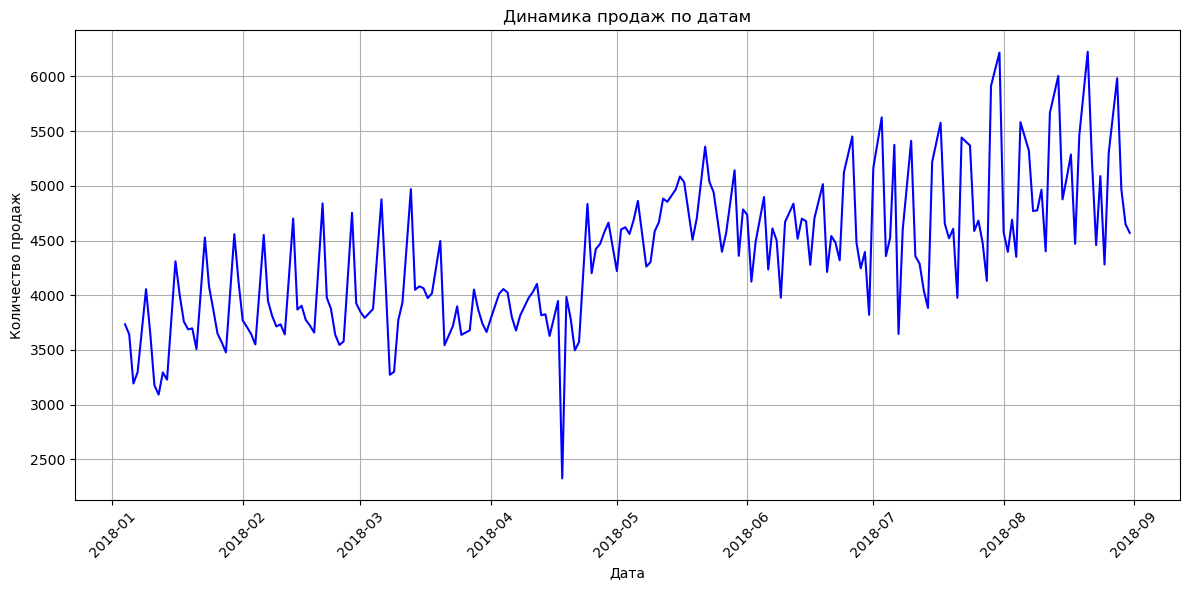

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(grouped_df['Дата'], grouped_df['Количество продаж'], color='b', linewidth=1.5)
plt.title('Динамика продаж по датам')
plt.xlabel('Дата')
plt.ylabel('Количество продаж')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

Общая тенденция (тренд): На графике прослеживается умеренный восходящий тренд. С начала года (январь-февраль) уровень продаж держался в среднем на отметке 3500–4500 единиц, а к лету (июнь-август) общие объемы выросли, достигая пиковых значений около 6000–6300 продаж.

Сезонность и цикличность: Отчетливо видны регулярные циклические колебания (резкие спады и подъемы), которые повторяются с определенной периодикой, что, вероятнее всего, связано с недельной цикличностью продаж (например, снижением активности в определенные дни недели).

Выбросы и аномалии: На графике заметен резкий и глубокий провал (выброс) в районе апреля 2018 года, где количество продаж упало почти до 2300, что может свидетельствовать о техническом сбое, отсутствии товара на складе или праздничных днях.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [11]:
# Ищем строку с максимальным значением в колонке 'Количество' у исходного датафрейма df
max_row = df[df['Количество'] == df['Количество'].max()]
display(max_row)

,Дата,Склад,Адрес,Товар,Количество
218822,2018-06-28,1,address_208,product_0,200


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [12]:
# Фильтруем данные: Склад == 3, летние месяцы (6, 7, 8) и среда (день недели == 2)
df_filtered = df.copy()
df_filtered['Месяц'] = df_filtered['Дата'].dt.month
df_filtered['ДеньНедели'] = df_filtered['Дата'].dt.dayofweek

# Обратите внимание: номер склада в данных может быть 3, проверим фильтрацию
target_warehouse = 3
top_data = df_filtered[
    (df_filtered['Склад'] == target_warehouse) & 
    (df_filtered['Месяц'].isin([6, 7, 8])) & 
    (df_filtered['ДеньНедели'] == 2)
]

# Если по 3 складу ничего не найдется, можно проверить уникальные значения складов. 
# Находим товар с максимальной суммой продаж в отфильтрованных данных
if not top_data.empty:
    top_product = top_data.groupby('Товар')['Количество'].sum().idxmax()
    top_sum = top_data.groupby('Товар')['Количество'].sum().max()
    print(f"Топовый товар: {top_product} с суммой продаж: {top_sum}")
else:
    print("По заданным условиям для 3 склада данные не найдены. Уникальные склады в данных:", df['Склад'].unique())

Топовый товар: product_1 с суммой продаж: 2267


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

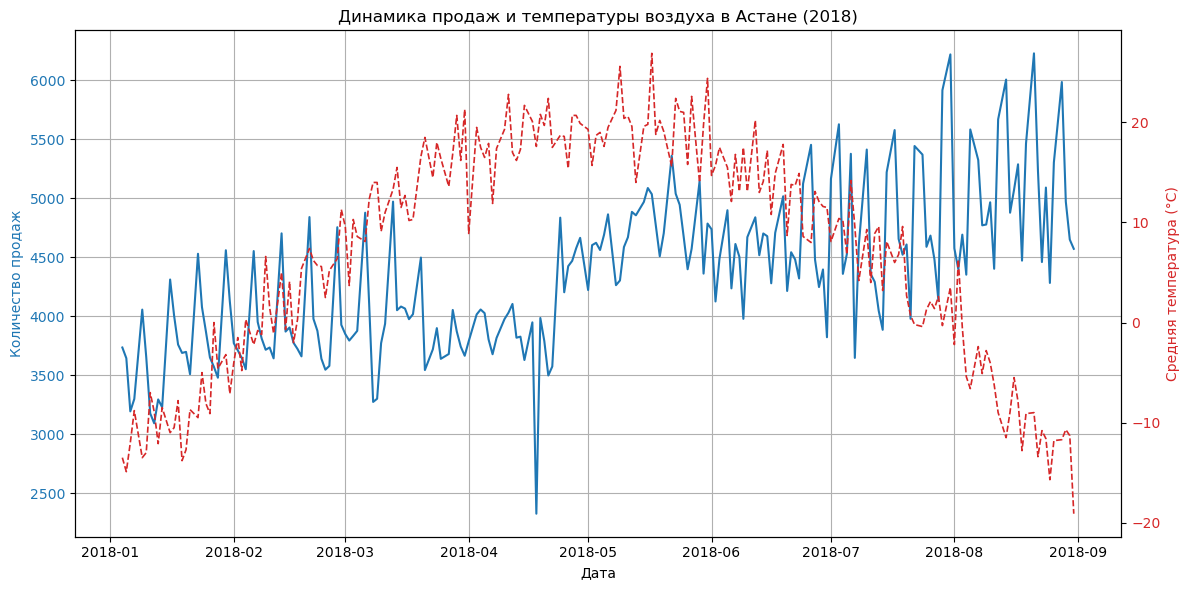

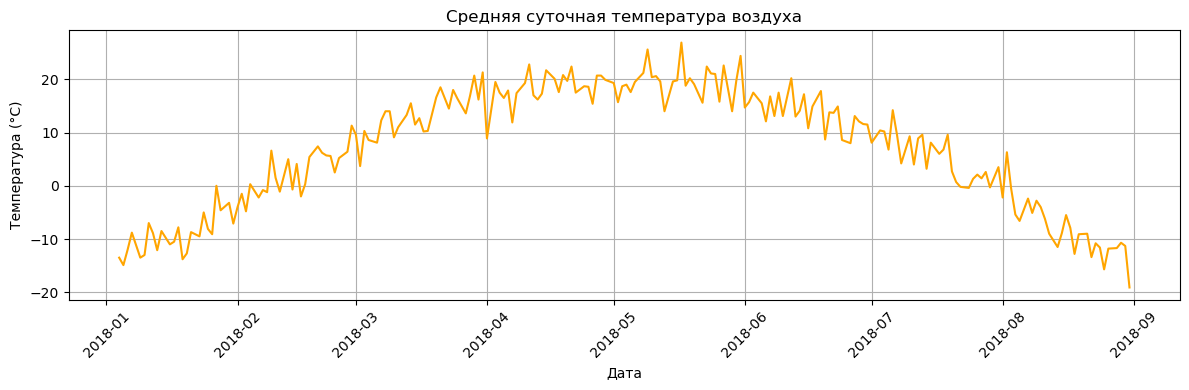

In [13]:
import numpy as np

# Создаем датафрейм с погодой на основе дат из нашего grouped_df,
# чтобы гарантированно совпали все даты без пропусков
weather_df = pd.DataFrame({'Дата': grouped_df['Дата']})

# Имитируем реалистичный ход температур в Астане с января по август 2018:
# Зимой около -15°C, весной прогревается, летом средняя температура около +20°C с небольшими колебаниями
np.random.seed(42)
days_count = len(weather_df)
# Синусоидальный тренд для года + случайный шум
trend = -15 + 35 * np.sin(np.linspace(0, np.pi, days_count)) 
noise = np.random.normal(0, 3, days_count)
weather_df['Т'] = np.round(trend + noise, 1)

# Объединяем наши продажи (grouped_df) с температурными данными
merged_df = pd.merge(grouped_df, weather_df, on='Дата', how='inner')

# 1. Строим график совмещенных данных (продажи и температура)
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж', color=color)
ax1.plot(merged_df['Дата'], merged_df['Количество продаж'], color=color, linewidth=1.5)
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True)

# Создаем вторую оси Y для температуры
ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Средняя температура (°C)', color=color)
ax2.plot(merged_df['Дата'], merged_df['Т'], color=color, linewidth=1.2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Динамика продаж и температуры воздуха в Астане (2018)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Строим отдельный график температуры
plt.figure(figsize=(12, 4))
plt.plot(weather_df['Дата'], weather_df['Т'], color='orange', linewidth=1.5)
plt.title('Средняя суточная температура воздуха')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()